In [5]:
import numpy as np
import matplotlib.pyplot as plt

In [9]:
#complete the values of the molecular energies and run the code below

molecules = ['hydrogen', 'methane', 'propane', 'ethanol', 'octane']

molecular_energies = {
    'hydrogen': -6.766,
    'methane': 297.000,
    'propane': 6334.000,
    'ethanol': 702.000,
    'octane': 10907.000,
    'oxygen': 977.000,
    'carbon dioxide': 280.000,
    'water': -14.472
}

In [10]:
atomic_masses = {'H': 1.00794,'C': 12.0107,'O': 15.9994} # g/mol

molecular_masses = {
    'hydrogen': 2 * atomic_masses['H'],
    'methane': 1 * atomic_masses['C'] + 4 * atomic_masses['H'],
    'propane': 3 * atomic_masses['C'] + 8 * atomic_masses['H'],
    'ethanol': 2 * atomic_masses['C'] + 6 * atomic_masses['H'] + 1 * atomic_masses['O'],
    'octane': 8 * atomic_masses['C'] + 18 * atomic_masses['H'],
    'oxygen': 2 * atomic_masses['O'],
    'carbon dioxide': 1 * atomic_masses['C'] + 2 * atomic_masses['O'],
    'water': 1 * atomic_masses['H'] + 2 * atomic_masses['O']
}

for molecule, mass in molecular_masses.items():
    print(f"{molecule:<20}: {mass:.5f} g/mol")

hydrogen            : 2.01588 g/mol
methane             : 16.04246 g/mol
propane             : 44.09562 g/mol
ethanol             : 46.06844 g/mol
octane              : 114.22852 g/mol
oxygen              : 31.99880 g/mol
carbon dioxide      : 44.00950 g/mol
water               : 33.00674 g/mol


In [11]:
combustion_energies = {
    'hydrogen': ( molecular_energies['water']) - ( 1 * molecular_energies['hydrogen'] + 0.5 * molecular_energies['oxygen']),
    'methane': (1 * molecular_energies['carbon dioxide'] + 2 * molecular_energies['water']) - (1 * molecular_energies['methane'] + 2 * molecular_energies['oxygen']),
    'propane': (3 * molecular_energies['carbon dioxide'] + 4 * molecular_energies['water']) - (1 * molecular_energies['propane'] + 5 * molecular_energies['oxygen']),
    'ethanol': (2 * molecular_energies['carbon dioxide'] + 3 * molecular_energies['water']) - (1 * molecular_energies['ethanol'] + 3 * molecular_energies['oxygen']),
    'octane': (8 * molecular_energies['carbon dioxide'] + 9 * molecular_energies['water']) - (1 * molecular_energies['octane'] + 12.5 * molecular_energies['oxygen'])
}

for molecule, energy_comb in combustion_energies.items():
    print(f"{molecule:<10}: {energy_comb:.5f} eV/molecule")

hydrogen  : -496.20600 eV/molecule
methane   : -1999.94400 eV/molecule
propane   : -10436.88800 eV/molecule
ethanol   : -3116.41600 eV/molecule
octane    : -21009.74800 eV/molecule


In [13]:
carbon_molecules = {           # number of CO2 molecules produced
    'hydrogen': 0,
    'methane': 1,
    'propane': 3,
    'ethanol': 2,
    'octane': 8,
}

# Some important unit conversions

In [15]:
EV_TO_JOULES = 1.602e-19        # J/eV
A = 6.022e23                    # molecules/mol
JOULES_TO_MJ = 1e-6             # MJ/J
EV_TO_MJ_PER_MOL = EV_TO_JOULES * A * JOULES_TO_MJ  # MJ/mol

# Calculate energy densities and carbon content

In [17]:
gravimetric_energy_density = -np.array(list(combustion_energies.values())[:5]) * EV_TO_MJ_PER_MOL / np.array(list(molecular_masses.values())[:5]) * 1e3  # MJ/kg

fuel_densities = {              # kg/L – known values
    'hydrogen': 0.0708,
    'methane': 0.422,
    'propane': 0.0020098,
    'ethanol': 0.789,
    'octane': 0.703,
}

volumetric_energy_density = gravimetric_energy_density * np.array(list(fuel_densities.values()))  # MJ/L

carbon_content = np.array(list(carbon_molecules.values())[:5]) / np.array(list(molecular_masses.values())[:5]) * 1000  # mol CO2/kg

# Plot energy and carbon content

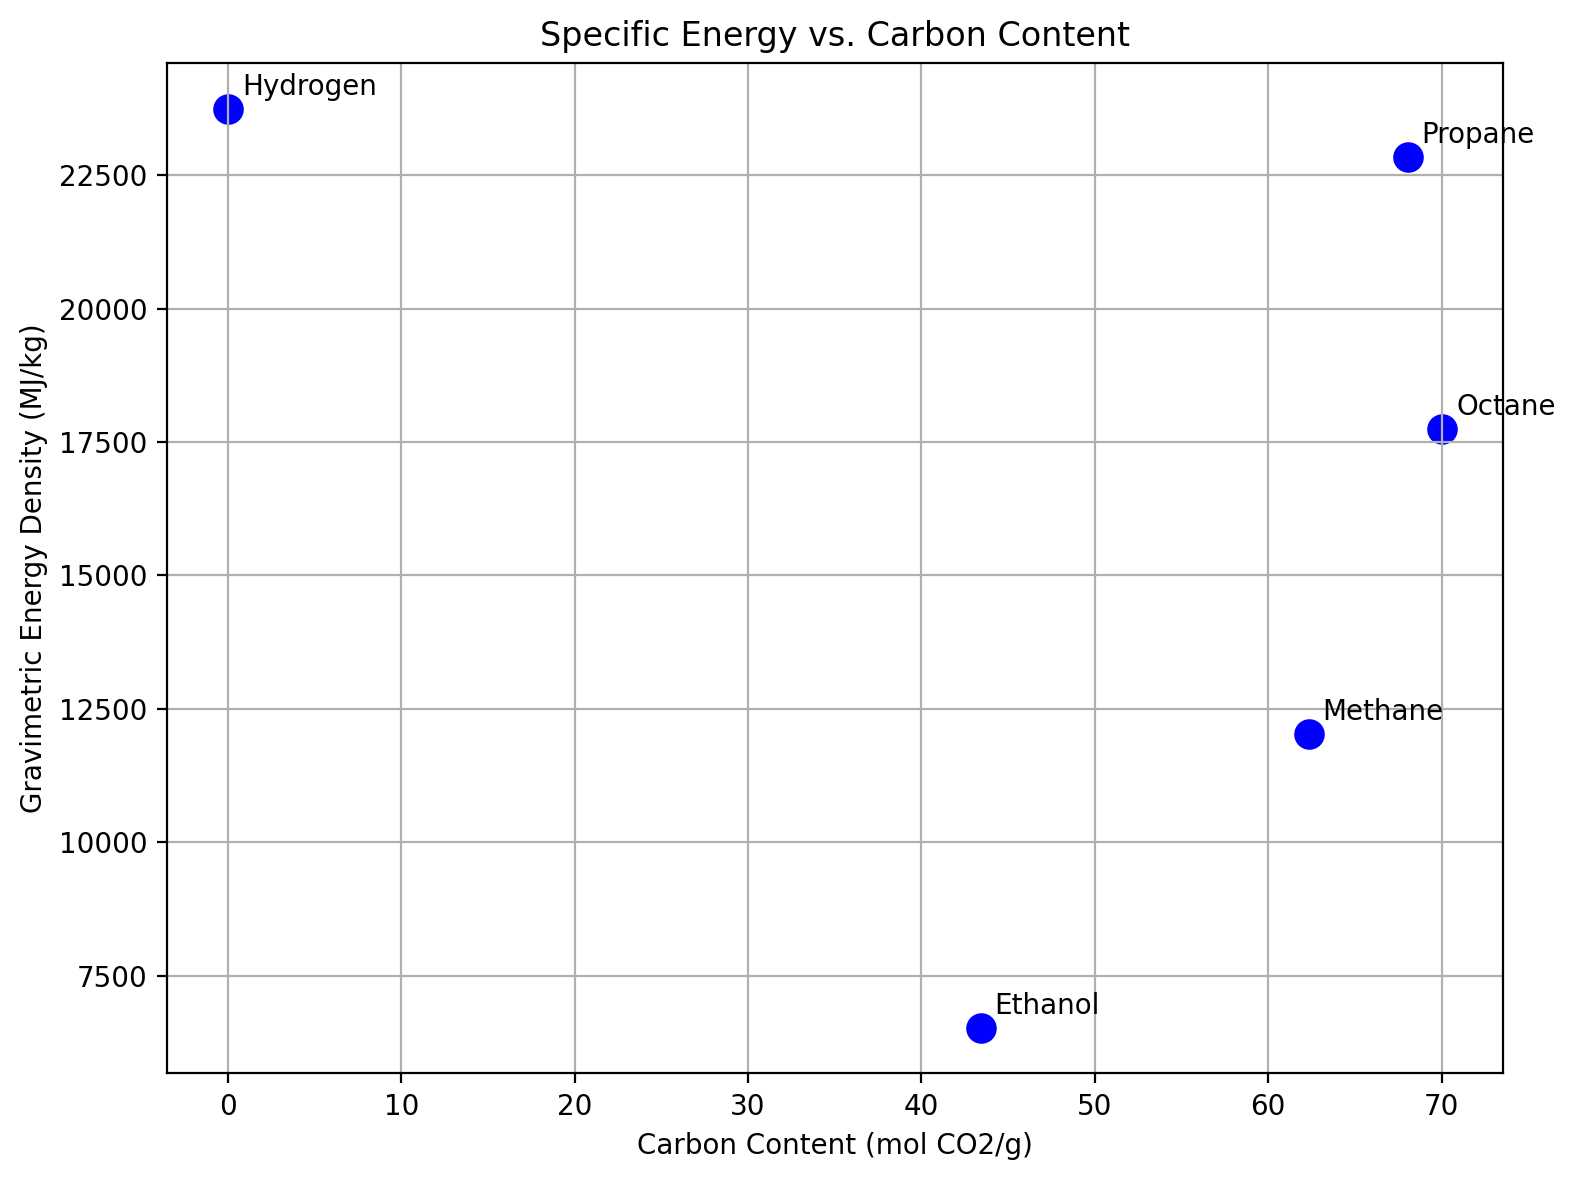

In [18]:
plt.figure(figsize=(8, 6), dpi=200)
plt.scatter(carbon_content, gravimetric_energy_density, color='blue', s=100)

for i, fuel in enumerate(molecules):
    plt.annotate(fuel.capitalize(), (carbon_content[i], gravimetric_energy_density[i]), xytext=(5, 5), textcoords='offset points')

plt.xlabel('Carbon Content (mol CO2/g)')
plt.ylabel('Gravimetric Energy Density (MJ/kg)')
plt.title('Specific Energy vs. Carbon Content')
plt.grid(True)
plt.tight_layout()
plt.show()

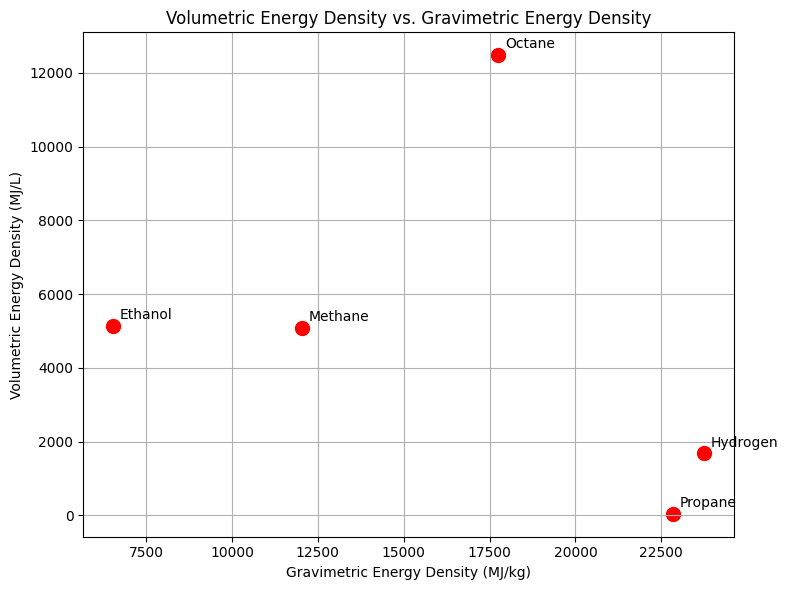

In [19]:
# volumetric energy density vs. gravimetric energy density
plt.figure(figsize=(8, 6))
plt.scatter(gravimetric_energy_density, volumetric_energy_density, color='red', s=100)
for i, fuel in enumerate(molecules):
    plt.annotate(fuel.capitalize(), (gravimetric_energy_density[i], volumetric_energy_density[i]), xytext=(5, 5), textcoords='offset points')
plt.xlabel('Gravimetric Energy Density (MJ/kg)')
plt.ylabel('Volumetric Energy Density (MJ/L)')
plt.title('Volumetric Energy Density vs. Gravimetric Energy Density')
plt.grid(True)
plt.tight_layout()
plt.show()